# Projeto 3 – Redes Neurais (MLP) na base B2W-Reviews01

Objetivo: prever a **nota (1 a 5 estrelas)** de uma avaliação de produto a partir do texto, com uma
**MLP de duas camadas ocultas implementada do zero** (forward, backpropagation pela regra da cadeia e
gradiente descendente com mini-batch), comparada com a mesma rede em **Keras**.

Base: [B2W-Reviews01](https://huggingface.co/datasets/fgops05/b2w-reviews01) – avaliações de clientes
da Americanas/B2W em português. É uma base difícil: 5 classes, desbalanceadas, e as notas vizinhas
(ex.: 4 e 5) têm textos muito parecidos.

# Carga dos dados

In [1]:
# ## Carga dos dados
# Bibliotecas básicas: numpy (contas com matrizes, usado em toda a MLP), pandas (tabelas)
# e matplotlib (gráficos).
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# [Requisito: base de texto difícil] A B2W-Reviews01 tem avaliações escritas por clientes (texto livre)
# e a nota de 1 a 5 estrelas: 5 classes desbalanceadas.
# O dataset do Hugging Face aponta para este CSV do repositório original da B2W (funciona no Colab).
# Lemos só as duas colunas usadas: o texto (entrada) e a nota (classe a prever).
URL = "https://raw.githubusercontent.com/americanas-tech/b2w-reviews01/4639429ec698d7821fc99a0bc665fa213d9fcd5a/B2W-Reviews01.csv"
df = pd.read_csv(URL, usecols=["review_text", "overall_rating"])

# Semente fixa: amostra, divisão dos dados e pesos iniciais saem sempre iguais, então o resultado é reproduzível.
SEED = 42
print(df.shape)
df.head()

(132373, 2)


,overall_rating,review_text
0,4,Estou contente com a compra entrega rápida o ú...
1,4,"Por apenas R$1994.20,eu consegui comprar esse ..."
2,4,SUPERA EM AGILIDADE E PRATICIDADE OUTRAS PANEL...
3,4,MEU FILHO AMOU! PARECE DE VERDADE COM TANTOS D...
4,5,"A entrega foi no prazo, as americanas estão de..."


# Estudo Introdutório

In [2]:
# ## Estudo introdutório: visão geral da base
# Mostra tamanho, nulos, duplicados e distribuição (absoluta e %) das notas.
# [Requisito: base desbalanceada] A tabela de distribuição mostra que as classes têm tamanhos muito diferentes.

print("Formato:", df.shape)
print("\nNulos por coluna:\n", df.isnull().sum())                      # avaliações sem texto
print("\nTextos duplicados:", df["review_text"].duplicated().sum())     # mesmo texto repetido

# Quantidade e porcentagem de avaliações em cada nota (1 a 5 estrelas).
dist = df["overall_rating"].value_counts().sort_index()
print("\nDistribuição das notas:")
print(pd.DataFrame({"qtd": dist, "%": (dist / len(df) * 100).round(2)}))

Formato: (132373, 2)

Nulos por coluna:
 overall_rating       0
review_text       3275
dtype: int64

Textos duplicados: 5648

Distribuição das notas:
                  qtd      %
overall_rating              
1               27369  20.68
2                8389   6.34
3               16315  12.33
4               32345  24.43
5               47955  36.23


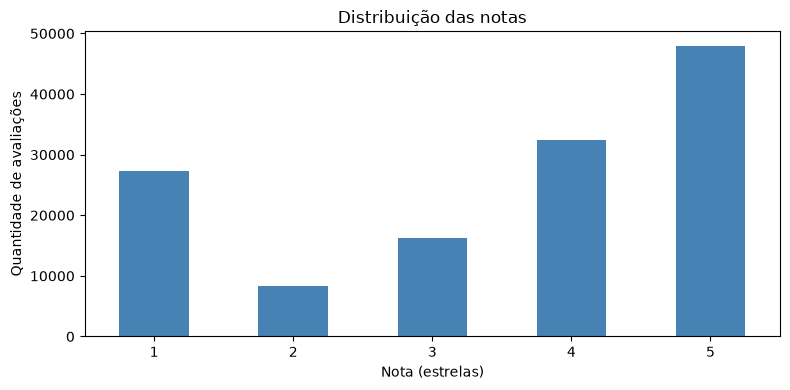

In [3]:
# ## Estudo introdutório: gráfico de distribuição das classes
# Barras com a quantidade de avaliações por nota, para visualizar o desbalanceamento.
# [Requisito: base desbalanceada] 5 estrelas é a maior classe e 2 estrelas a menor.

dist.plot(kind="bar", figsize=(8, 4), color="steelblue")
plt.title("Distribuição das notas")
plt.xlabel("Nota (estrelas)")
plt.ylabel("Quantidade de avaliações")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:
# ## Estudo introdutório: tamanho dos textos
# Calcula nº de palavras por avaliação e mostra estatísticas gerais e a média por nota.
# Serve para entender a base: as avaliações negativas tendem a ser mais longas.

df["n_palavras"] = df["review_text"].str.split().str.len()   # conta palavras separando por espaço
print(df["n_palavras"].describe())
print("\nMédia de palavras por nota:")
print(df.groupby("overall_rating")["n_palavras"].mean().round(1))

count    129098.000000
mean         23.022665
std          22.152798
min           1.000000
25%          11.000000
50%          16.000000
75%          27.000000
max         795.000000
Name: n_palavras, dtype: float64

Média de palavras por nota:
overall_rating
1    33.3
2    31.0
3    24.0
4    18.9
5    18.5
Name: n_palavras, dtype: float64


In [5]:
# ## Estudo introdutório: exemplos por nota
# Imprime 2 avaliações aleatórias de cada nota para entender o conteúdo.
# Ajuda a ver por que a tarefa é difícil: notas vizinhas (ex.: 4 e 5) usam palavras parecidas.

for nota in sorted(df["overall_rating"].unique()):
    print(f"\n=== {nota} estrela(s) ===")
    for t in df[df["overall_rating"] == nota]["review_text"].dropna().sample(2, random_state=SEED):
        print("-", t[:200])   # mostra só os primeiros 200 caracteres


=== 1 estrela(s) ===
- Uma kaka comprei esperei 2 meses e não chegou nada e ainda não peguei meu dinheiro de volta.
- Produto veio estragado. Estou há 1 mês sem saber o q será feito com o produto!!!

=== 2 estrela(s) ===
- Recebi a tinta certa, mas o vidro de verniz veio vazio. Nao pude usar o produto.
- A parte que compõe o jogo o  da bacia sanitária é de tnt é é frágil

=== 3 estrela(s) ===
- O Produto está dentro das expectativas, mas a vendedora não encaminhou junto a bolsa que deria acompanhar o produto. Acionada por um dos canais de comunicação disponibilizados, limitou-se a indicar ou
- após carregar o aparelho por 10 horas por duas vezes, ele nao pisca o led para avisar que está carregado e no manual diz que pisca quando está com a carga completa. isso nao aconteceu por duas vezes q

=== 4 estrela(s) ===
- Qualidade muito boa recomendo, material bastante resistente e o tamanho ideal
- O Celular é muito bom, ate hoje não tive nenhum problema.

=== 5 estrela(s) ===
- Atende minh

**Análise:** a base tem 132.373 avaliações e é **desbalanceada**: 36% são de 5 estrelas e só 6% de 2 estrelas.
Há 3.275 textos vazios e 5.648 duplicados, removidos antes da divisão. As avaliações negativas são mais longas
(33 palavras em média para 1 estrela contra 18,5 para 5 estrelas): quem reclama explica o problema. Pelos exemplos,
notas vizinhas usam vocabulário parecido ("muito bom, recomendo" aparece em 4 e em 5 estrelas), o que torna a tarefa difícil.

# Preparação dos dados

In [6]:
# ## Limpeza e amostra estratificada
# Remove textos nulos e duplicados (evita o mesmo texto no treino e no teste) e sorteia 20 mil
# avaliações mantendo a proporção das notas, para que a MLP feita em numpy rode em poucos minutos.

N_AMOSTRA = 20000

# Limpeza: sem texto não há o que classificar, e um texto repetido poderia cair no treino e no
# teste ao mesmo tempo (vazamento de dados).
antes = len(df)
df = df.dropna(subset=["review_text"]).drop_duplicates(subset="review_text").reset_index(drop=True)
print(f"Removidos (nulos + duplicados): {antes - len(df)} | Restantes: {len(df)}")

# Amostra estratificada: sorteia a mesma fração de cada nota, então o desbalanceamento original é mantido.
amostra = df.groupby("overall_rating", group_keys=False).sample(frac=N_AMOSTRA / len(df), random_state=SEED)
print("Amostra:", len(amostra))
print((amostra["overall_rating"].value_counts(normalize=True).sort_index() * 100).round(2))

Removidos (nulos + duplicados): 5649 | Restantes: 126724
Amostra: 20000
overall_rating
1    19.42
2     6.30
3    12.50
4    25.08
5    36.68
Name: proportion, dtype: float64


overall_rating
1    32.8
2    30.9
3    23.9
4    18.9
5    18.5
Name: n_palavras, dtype: float64


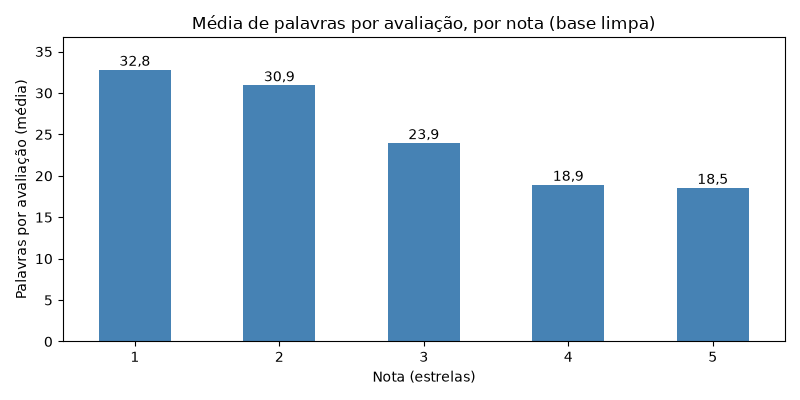

In [ ]:
# ## Média de palavras por nota (base limpa)
# Barras com o número médio de palavras por avaliação em cada nota, depois da remoção de nulos e duplicados.

media = df.groupby("overall_rating")["n_palavras"].mean()
print(media.round(1))

ax = media.plot(kind="bar", figsize=(8, 4), color="steelblue")
for i, v in enumerate(media):                       # escreve o valor em cima de cada barra
    ax.text(i, v + 0.5, f"{v:.1f}".replace(".", ","), ha="center")
ax.set_ylim(0, media.max() * 1.12)                  # folga no topo para os rótulos
plt.title("Média de palavras por avaliação, por nota (base limpa)")
plt.xlabel("Nota (estrelas)")
plt.ylabel("Palavras por avaliação (média)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
# ## Split: 80% desenvolvimento (3-fold CV) e 20% teste
# O teste fica reservado e só é usado no final. As classes viram 0..4 (nota - 1).
# Os 80% de desenvolvimento são usados no 3-fold cross-validation (escolha dos hiperparâmetros) e
# depois para treinar o modelo final.

from sklearn.model_selection import train_test_split

# stratify mantém a mesma proporção de cada nota no desenvolvimento e no teste.
X_dev_txt, X_test_txt, y_dev, y_test = train_test_split(
    amostra["review_text"], amostra["overall_rating"].to_numpy() - 1,
    test_size=0.20, stratify=amostra["overall_rating"], random_state=SEED
)
print(f"Desenvolvimento: {len(X_dev_txt)} | Teste: {len(X_test_txt)}")
print("Por classe (dev):", np.bincount(y_dev), "| (teste):", np.bincount(y_test))

Desenvolvimento: 16000 | Teste: 4000
Por classe (dev): [3107 1009 2001 4014 5869] | (teste): [ 777  252  500 1003 1468]


In [8]:
# ## TF-IDF sobre os textos
# Mesmo TF-IDF do projeto anterior (palavras e pares de palavras, sem números), com 3.000 termos.
# O vocabulário é aprendido só no desenvolvimento, para não vazar informação do teste.
# Técnica: TF-IDF transforma cada texto num vetor de números (um peso por termo). É a ENTRADA da MLP:
# cada avaliação vira 3.000 valores, um para cada neurônio da camada de entrada.

from sklearn.feature_extraction.text import TfidfVectorizer

# ngram_range=(1, 2): palavras sozinhas e pares de palavras; min_df/max_df descartam termos raros
# (menos de 2 textos) e comuns demais (mais da metade dos textos); o token_pattern ignora números.
tfidf = TfidfVectorizer(max_features=3000, ngram_range=(1, 2), min_df=2, max_df=0.5,
                        lowercase=True, token_pattern=r"(?u)\b[^\W\d_]{2,}\b")
X_dev = tfidf.fit_transform(X_dev_txt).astype(np.float32)   # fit: aprende o vocabulário (só no dev)
X_test = tfidf.transform(X_test_txt).astype(np.float32)     # transform: só aplica o vocabulário no teste
termos = tfidf.get_feature_names_out()                      # nome de cada coluna (usado no mapa de calor)
print("Formato dev:", X_dev.shape, "| teste:", X_test.shape)

Formato dev: (16000, 3000) | teste: (4000, 3000)


# MLP implementada do zero

**Arquitetura:** entrada (3.000 termos TF-IDF) → camada oculta 1 → camada oculta 2 → saída com
5 neurônios (um por classe) e **softmax**, com **entropia cruzada** como função de custo – o padrão para
classificação multiclasse.

**Forward pass:** em cada camada, $z = aW + b$ e $a = f(z)$, com $f$ = ReLU ou Sigmoid nas ocultas.

**Backpropagation (regra da cadeia):** o erro da saída é propagado para trás usando os mesmos pesos
do forward e multiplicado pela derivada da função de ativação de cada neurônio:

* saída (softmax + entropia cruzada): $\delta^{(3)} = \hat{y} - y$
* camadas ocultas: $\delta^{(l)} = (\delta^{(l+1)} W^{(l+1)T}) \odot f'(z^{(l)})$ – como em $\delta_4 = w_{46}\,\delta$
  seguido de $\frac{df_4(e)}{de}$
* derivada dos **pesos**: $\frac{\partial C}{\partial W^{(l)}} = a^{(l-1)T}\,\delta^{(l)}$ (+ $2\lambda W^{(l)}$ com L2)
* derivada do **bias**: $\frac{\partial C}{\partial b^{(l)}} = \sum \delta^{(l)}$

**Atualização (gradiente descendente):** $W \leftarrow W - \eta \frac{\partial C}{\partial W}$ e
$b \leftarrow b - \eta \frac{\partial C}{\partial b}$, por mini-batch de 32 instâncias. É a mesma regra
$w'_{14} = w_{14} + \eta\,\delta_4 \frac{df_4(e)}{de} y_1$, escrita com o erro $\hat{y} - y$ (por isso o sinal de menos).

**Regularização L2:** soma $\lambda \sum W^2$ ao custo (só nos pesos, não no bias), o que acrescenta
$2\lambda W$ ao gradiente – igual ao `kernel_regularizer=l2(λ)` do Keras.

In [9]:
# ## Funções de ativação e suas derivadas
# [Requisito: 2 funções de ativação, ReLU e Sigmoid] As duas pedidas no trabalho, cada uma com sua
# derivada. A derivada é usada no backpropagation (regra da cadeia): o erro que volta por um neurônio
# é multiplicado por f'(z).

# ReLU: f(z) = max(0, z). Derivada 1 quando o neurônio está ativo (z > 0) e 0 quando está desligado.
def relu(z):
    return np.maximum(0, z)

def relu_derivada(z):
    return (z > 0).astype(z.dtype)

# Sigmoid: f(z) = 1 / (1 + e^-z), saída entre 0 e 1. Derivada f(z)·(1 - f(z)), que vale no máximo 0,25
# (por isso o erro enfraquece a cada camada; ver a análise de saturação).
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivada(z):
    s = sigmoid(z)
    return s * (1 - s)

# Ativação linear (identidade): não faz parte da grade de hiperparâmetros.
def linear(z):                       # usada só na camada de embedding do Skip-gram
    return z

def linear_derivada(z):
    return np.ones_like(z)

# Dicionário para a classe MLP escolher a ativação pelo nome ("relu", "sigmoid" ou "linear").
ATIVACOES = {"relu": (relu, relu_derivada),
             "sigmoid": (sigmoid, sigmoid_derivada),
             "linear": (linear, linear_derivada)}

# Softmax: usada na camada de saída. Transforma os 5 valores de saída em probabilidades que somam 1,
# uma para cada nota.
def softmax(z):
    e = np.exp(z - z.max(axis=1, keepdims=True))   # subtrai o máximo para evitar overflow
    return e / e.sum(axis=1, keepdims=True)

In [10]:
# ## Classe MLP: forward, backpropagation (regra da cadeia), treino e predição
# [Requisito: implementar uma MLP com duas camadas] Rede feita do zero, só com numpy.
# Com camadas = [3000, n1, n2, 5] ela tem duas camadas ocultas (n1 e n2 neurônios variam na grade).
# [Requisito: derivada em cadeia, derivadas dos pesos E do bias] Ficam no método backward().
# [Requisito: mapa de calor] O fit() também guarda quanto cada peso mudou em cada época.

from sklearn.metrics import f1_score, accuracy_score


class MLP:
    def __init__(self, camadas, ativacao="relu", l2=0.0, lr=0.1, epocas=30, batch=32, seed=SEED):
        # camadas = [n_entrada, n_oculta1, n_oculta2, n_saida]
        # ativacao: "relu" ou "sigmoid" nas camadas ocultas; l2: força da regularização (0 = sem);
        # lr: taxa de aprendizado do gradiente descendente; batch: tamanho do mini-batch.
        self.camadas = camadas
        self.f, self.f_derivada = ATIVACOES[ativacao]
        self.l2, self.lr, self.epocas, self.batch = l2, lr, epocas, batch
        self.rng = np.random.default_rng(seed)
        # inicialização Glorot uniforme (a mesma padrão do Keras) e bias zero
        # Uma matriz de pesos W e um vetor de bias b para cada ligação entre duas camadas.
        self.W, self.b = [], []
        for n_in, n_out in zip(camadas[:-1], camadas[1:]):
            limite = np.sqrt(6 / (n_in + n_out))
            self.W.append(self.rng.uniform(-limite, limite, (n_in, n_out)).astype(np.float32))
            self.b.append(np.zeros(n_out, dtype=np.float32))

    # ---------- forward pass ----------
    # Passa a entrada pela rede, camada por camada: z = a·W + b e a = f(z).
    # Nas ocultas f é ReLU ou Sigmoid; na última camada é a softmax (probabilidade de cada nota).
    # Guarda os z e as ativações porque o backpropagation precisa deles.
    def forward(self, X):
        zs, ativs = [], [X]                      # ativs[0] é a entrada
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            z = ativs[-1] @ W + b
            zs.append(z)
            ultima = i == len(self.W) - 1
            ativs.append(softmax(z) if ultima else self.f(z))
        return zs, ativs

    # ---------- backpropagation: derivadas dos pesos e do bias ----------
    # Regra da cadeia, da saída para a entrada:
    #   1. erro da saída: δ = ŷ - y (derivada da entropia cruzada com softmax);
    #   2. em cada camada: derivada dos pesos = aᵀ·δ e derivada do bias = Σδ;
    #   3. o erro volta para a camada anterior pelos mesmos pesos W (δ·Wᵀ) e é multiplicado
    #      pela derivada da ativação f'(z).
    def backward(self, zs, ativs, y):
        m = len(y)
        dW, db = [None] * len(self.W), [None] * len(self.b)
        delta = ativs[-1].copy()                 # δ da saída = ŷ - y (softmax + entropia cruzada)
        delta[np.arange(m), y] -= 1
        delta /= m                               # média no mini-batch
        for i in reversed(range(len(self.W))):
            # [Requisito: L2 × sem regularização] Com L2, soma 2λW na derivada dos pesos (o bias não é regularizado).
            dW[i] = np.asarray(ativs[i].T @ delta) + 2 * self.l2 * self.W[i]   # ∂C/∂W = aᵀδ (+ L2)
            db[i] = delta.sum(axis=0)                                           # ∂C/∂b = Σδ
            if i > 0:                                                           # δ volta pelos pesos W
                delta = (delta @ self.W[i].T) * self.f_derivada(zs[i - 1])      # e pela derivada f'(z)
        return dW, db

    # ---------- custo, predição ----------
    # Custo = entropia cruzada média + λ·ΣW² (termo da L2, zero quando l2 = 0).
    # É o valor plotado nas curvas de aprendizado.
    def custo(self, X, y):
        p = self.forward(X)[1][-1]
        entropia = -np.log(p[np.arange(len(y)), y] + 1e-12).mean()
        return entropia + self.l2 * sum((W ** 2).sum() for W in self.W)

    def predict_proba(self, X):
        return self.forward(X)[1][-1]

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)     # classe com maior probabilidade

    # ---------- treino por mini-batch ----------
    # Gradiente descendente: em cada época, embaralha os dados, percorre mini-batches de 32 e,
    # a cada lote, faz forward → backward → atualização W ← W - lr·dW e b ← b - lr·db.
    def fit(self, X, y, X_val=None, y_val=None, historico=True):
        self.hist = {k: [] for k in ["custo_treino", "custo_val", "acc_treino", "acc_val", "f1_treino", "f1_val"]}
        # [Requisito: mapa de calor] Acumuladores da variação dos pesos, preenchidos ao fim de cada época.
        self.variacao = [np.zeros_like(W) for W in self.W]   # |ΔW| acumulado época a época
        self.variacao_epoca = []                             # Σ|ΔW| de cada camada em cada época
        n = X.shape[0]
        for epoca in range(self.epocas):
            W_antes = [W.copy() for W in self.W]              # foto dos pesos no início da época
            idx = self.rng.permutation(n)                     # em cada época, nova ordem aleatória
            for ini in range(0, n, self.batch):
                lote = idx[ini:ini + self.batch]
                zs, ativs = self.forward(X[lote])
                dW, db = self.backward(zs, ativs, y[lote])
                for i in range(len(self.W)):                  # gradiente descendente
                    self.W[i] -= self.lr * dW[i]
                    self.b[i] -= self.lr * db[i]
            # Quanto cada peso mudou nesta época, somado ao acumulado (é o que vira o mapa de calor).
            delta_W = [np.abs(W - Wa) for W, Wa in zip(self.W, W_antes)]
            for i, d in enumerate(delta_W):
                self.variacao[i] += d
            self.variacao_epoca.append([d.sum() for d in delta_W])
            # [Requisito: curvas de aprendizado] Ao fim de cada época, guarda custo, acurácia e F1 macro
            # no treino e na validação. Essas listas viram as curvas.
            if historico:
                p_tr, p_va = self.predict(X), self.predict(X_val)
                self.hist["custo_treino"].append(self.custo(X, y))
                self.hist["custo_val"].append(self.custo(X_val, y_val))
                self.hist["acc_treino"].append(accuracy_score(y, p_tr))
                self.hist["acc_val"].append(accuracy_score(y_val, p_va))
                self.hist["f1_treino"].append(f1_score(y, p_tr, average="macro"))
                self.hist["f1_val"].append(f1_score(y_val, p_va, average="macro"))
        return self

## Conferência das derivadas (pesos e bias)

Para garantir que a regra da cadeia está correta, as derivadas calculadas pelo backpropagation são
comparadas com a **derivada numérica** $\frac{C(w+\epsilon) - C(w-\epsilon)}{2\epsilon}$ numa rede pequena.

In [11]:
# ## Gradiente analítico (backpropagation) × gradiente numérico
# [Requisito: a implementação deve atender as derivadas dos pesos e do bias]
# Prova de que a regra da cadeia está certa: para cada peso e cada bias de uma rede pequena,
# compara a derivada calculada pelo backward() com a derivada numérica
# (C(w + ε) - C(w - ε)) / 2ε. Se as duas baterem, o backpropagation está correto.

def conferir_gradientes(ativacao, l2):
    rede = MLP([6, 5, 4, 3], ativacao=ativacao, l2=l2)          # rede pequena, também com 2 camadas ocultas
    rede.W = [W.astype(np.float64) for W in rede.W]               # float64 para a conta numérica ser precisa
    rede.b = [b.astype(np.float64) + 0.1 for b in rede.b]     # bias ≠ 0 para testar sua derivada
    rng = np.random.default_rng(0)
    X, y = rng.normal(size=(8, 6)), rng.integers(0, 3, 8)       # 8 exemplos aleatórios
    zs, ativs = rede.forward(X)
    dW, db = rede.backward(zs, ativs, y)                          # derivadas pelo backpropagation
    eps, maior_erro = 1e-6, 0.0
    for params, grads in [(rede.W, dW), (rede.b, db)]:            # primeiro os pesos, depois os bias
        for P, G in zip(params, grads):
            for idx in np.ndindex(P.shape):
                original = P[idx]
                P[idx] = original + eps; c_mais = rede.custo(X, y)
                P[idx] = original - eps; c_menos = rede.custo(X, y)
                P[idx] = original
                maior_erro = max(maior_erro, abs((c_mais - c_menos) / (2 * eps) - G[idx]))
    return maior_erro

# Testa as duas ativações, com e sem L2. Diferença perto de zero (~1e-10) = derivadas corretas.
for ativacao in ["relu", "sigmoid"]:
    for l2 in [0.0, 1e-3]:
        print(f"{ativacao:8s} L2={l2:<6} maior diferença: {conferir_gradientes(ativacao, l2):.2e}")

relu     L2=0.0    maior diferença: 1.57e-10
relu     L2=0.001  maior diferença: 2.27e-10
sigmoid  L2=0.0    maior diferença: 1.93e-10
sigmoid  L2=0.001  maior diferença: 2.27e-10


**Análise:** a maior diferença entre a derivada calculada pelo backpropagation e a derivada numérica é da ordem de
$10^{-10}$, para as duas ativações, com e sem L2. Ou seja, a regra da cadeia está correta tanto para os **pesos** quanto para
os **bias** de todas as camadas.

# Escolha dos hiperparâmetros com 3-fold cross-validation

Variações avaliadas (grid search): **ativação** ReLU ou Sigmoid × **regularização** sem ou L2 ×
**neurônios** nas duas camadas ocultas (modelo pirâmide): (16, 8), (64, 32) e (128, 64) – 12 configurações.

Fixos para todas: SGD com mini-batch de 32, taxa de aprendizado 0,1, 30 épocas, λ = 0,001 na L2.
Cada configuração é treinada 3 vezes (uma por fold); o desempenho é a média nos folds de validação.
Como a base é desbalanceada, a escolha usa o **F1 macro** (média do F1 de cada classe); a acurácia
também é mostrada.

In [12]:
# ## Grid search com 3-fold cross-validation (pode levar ~15 min)
# [Requisito: variações de hiperparâmetros] ativação (ReLU × Sigmoid), regularização (L2 × sem) e
# número de neurônios por camada: 2 × 2 × 3 = 12 configurações.
# [Requisito: aplicar 3-fold cross-validation para escolher os melhores hiperparâmetros]

import itertools, time
from sklearn.model_selection import StratifiedKFold

# Parâmetros fixos em todas as configurações (as mesmas condições para todas).
EPOCAS, BATCH, LR, LAMBDA_L2 = 30, 32, 0.1, 1e-3
ATIVACOES_GRID = ["relu", "sigmoid"]
REGULARIZACOES = {"sem": 0.0, "L2": LAMBDA_L2}
NEURONIOS = [(16, 8), (64, 32), (128, 64)]          # (camada oculta 1, camada oculta 2), formato pirâmide

# 3 folds estratificados: cada configuração treina 3 vezes com 2/3 do desenvolvimento e valida no 1/3 restante.
folds = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED).split(X_dev, y_dev))

resultados, historicos = [], {}
inicio = time.time()
# itertools.product monta todas as combinações da grade (grid search).
for ativacao, reg, (n1, n2) in itertools.product(ATIVACOES_GRID, REGULARIZACOES, NEURONIOS):
    nome = f"{ativacao} | {reg} | ({n1},{n2})"
    hists = []
    for k, (tr, va) in enumerate(folds):
        # MLP com duas camadas ocultas: 3000 entradas → n1 → n2 → 5 saídas
        rede = MLP([X_dev.shape[1], n1, n2, 5], ativacao=ativacao, l2=REGULARIZACOES[reg],
                   lr=LR, epocas=EPOCAS, batch=BATCH)
        rede.fit(X_dev[tr], y_dev[tr], X_dev[va], y_dev[va])
        hists.append(rede.hist)
    # Média dos 3 folds, época a época: é o que vai para a tabela e para as curvas de aprendizado.
    historicos[nome] = {k: np.mean([h[k] for h in hists], axis=0) for k in hists[0]}
    h = historicos[nome]
    resultados.append({"configuração": nome, "ativação": ativacao, "regularização": reg, "neurônios": (n1, n2),
                       "acc treino": h["acc_treino"][-1], "acc val": h["acc_val"][-1],
                       "F1 macro treino": h["f1_treino"][-1], "F1 macro val": h["f1_val"][-1],
                       "custo treino": h["custo_treino"][-1], "custo val": h["custo_val"][-1]})
    print(f"{nome:28s} F1 val = {h['f1_val'][-1]:.3f} | acc val = {h['acc_val'][-1]:.3f}  ({time.time() - inicio:.0f}s)")

# Tabela final ordenada pelo F1 macro na validação (melhor no topo).
resultados = pd.DataFrame(resultados).sort_values("F1 macro val", ascending=False).reset_index(drop=True)
resultados.round(3)

relu | sem | (16,8)          F1 val = 0.459 | acc val = 0.558  (8s)


relu | sem | (64,32)         F1 val = 0.391 | acc val = 0.496  (26s)


relu | sem | (128,64)        F1 val = 0.415 | acc val = 0.518  (58s)


relu | L2 | (16,8)           F1 val = 0.401 | acc val = 0.554  (66s)


relu | L2 | (64,32)          F1 val = 0.341 | acc val = 0.466  (81s)


relu | L2 | (128,64)         F1 val = 0.393 | acc val = 0.508  (113s)


... (3 outputs left out)

sigmoid | L2 | (16,8)        F1 val = 0.107 | acc val = 0.367  (181s)


sigmoid | L2 | (64,32)       F1 val = 0.107 | acc val = 0.367  (200s)


sigmoid | L2 | (128,64)      F1 val = 0.107 | acc val = 0.367  (240s)


,configuração,ativação,regularização,neurônios,acc treino,acc val,F1 macro treino,F1 macro val,custo treino,custo val
0,"relu | sem | (16,8)",relu,sem,"(16, 8)",0.734,0.558,0.677,0.459,0.611,1.182
1,"relu | sem | (128,64)",relu,sem,"(128, 64)",0.814,0.518,0.786,0.415,0.540,1.827
2,"relu | L2 | (16,8)",relu,L2,"(16, 8)",0.613,0.554,0.459,0.401,1.012,1.202
3,"relu | L2 | (128,64)",relu,L2,"(128, 64)",0.587,0.508,0.476,0.393,1.183,1.476
4,"relu | sem | (64,32)",relu,sem,"(64, 32)",0.786,0.496,0.748,0.391,0.827,1.989
5,"sigmoid | sem | (16,8)",sigmoid,sem,"(16, 8)",0.543,0.528,0.357,0.347,1.046,1.075
6,"relu | L2 | (64,32)",relu,L2,"(64, 32)",0.526,0.466,0.409,0.341,1.397,1.678
7,"sigmoid | sem | (64,32)",sigmoid,sem,"(64, 32)",0.520,0.513,0.328,0.322,1.076,1.124
8,"sigmoid | sem | (128,64)",sigmoid,sem,"(128, 64)",0.508,0.501,0.277,0.273,1.147,1.172
9,"sigmoid | L2 | (16,8)",sigmoid,L2,"(16, 8)",0.367,0.367,0.107,0.107,1.470,1.470


In [13]:
# ## Melhor configuração (maior F1 macro médio na validação)
# [Requisito: escolher os melhores hiperparâmetros] Fica com a primeira linha da tabela ordenada.
# O F1 macro dá o mesmo peso a todas as notas, por isso é o critério numa base desbalanceada.
# Essa configuração é usada no modelo final, na comparação com o Keras, nos mapas de calor e no Skip-gram.

melhor = resultados.iloc[0]
MELHOR_ATIV, MELHOR_REG, MELHOR_NEUR = melhor["ativação"], melhor["regularização"], melhor["neurônios"]
print("Melhor configuração:", melhor["configuração"])
print(f"F1 macro val = {melhor['F1 macro val']:.3f} | acurácia val = {melhor['acc val']:.3f}")

Melhor configuração: relu | sem | (16,8)
F1 macro val = 0.459 | acurácia val = 0.558


**Análise:** a melhor configuração foi **ReLU, sem regularização, com (16, 8) neurônios** (F1 macro 0,459 e acurácia 0,558
na média dos 3 folds de validação).

* **ReLU × Sigmoid:** a ReLU vence em todas as combinações. Com Sigmoid a rede aprende muito mais devagar (ver curvas e saturação).
* **Número de neurônios:** com ReLU, a rede menor foi a melhor; as maiores decoram mais o treino (acurácia de treino 0,79–0,81)
  sem ganhar na validação.
* **L2:** com λ = 0,001 a regularização reduziu a diferença entre treino e validação, mas também o desempenho: foi forte demais para esta base.
  Na Sigmoid, a L2 impediu o aprendizado – a rede prevê sempre 5 estrelas (acurácia 0,367 = proporção dessa classe; F1 macro 0,107).

# Curvas de aprendizado: overfitting, underfitting, viés e variância

Para cada configuração, o custo (entropia cruzada) no treino e na validação ao longo das épocas,
na média dos 3 folds. Mesmo padrão de cores das curvas de aprendizado do projeto anterior.

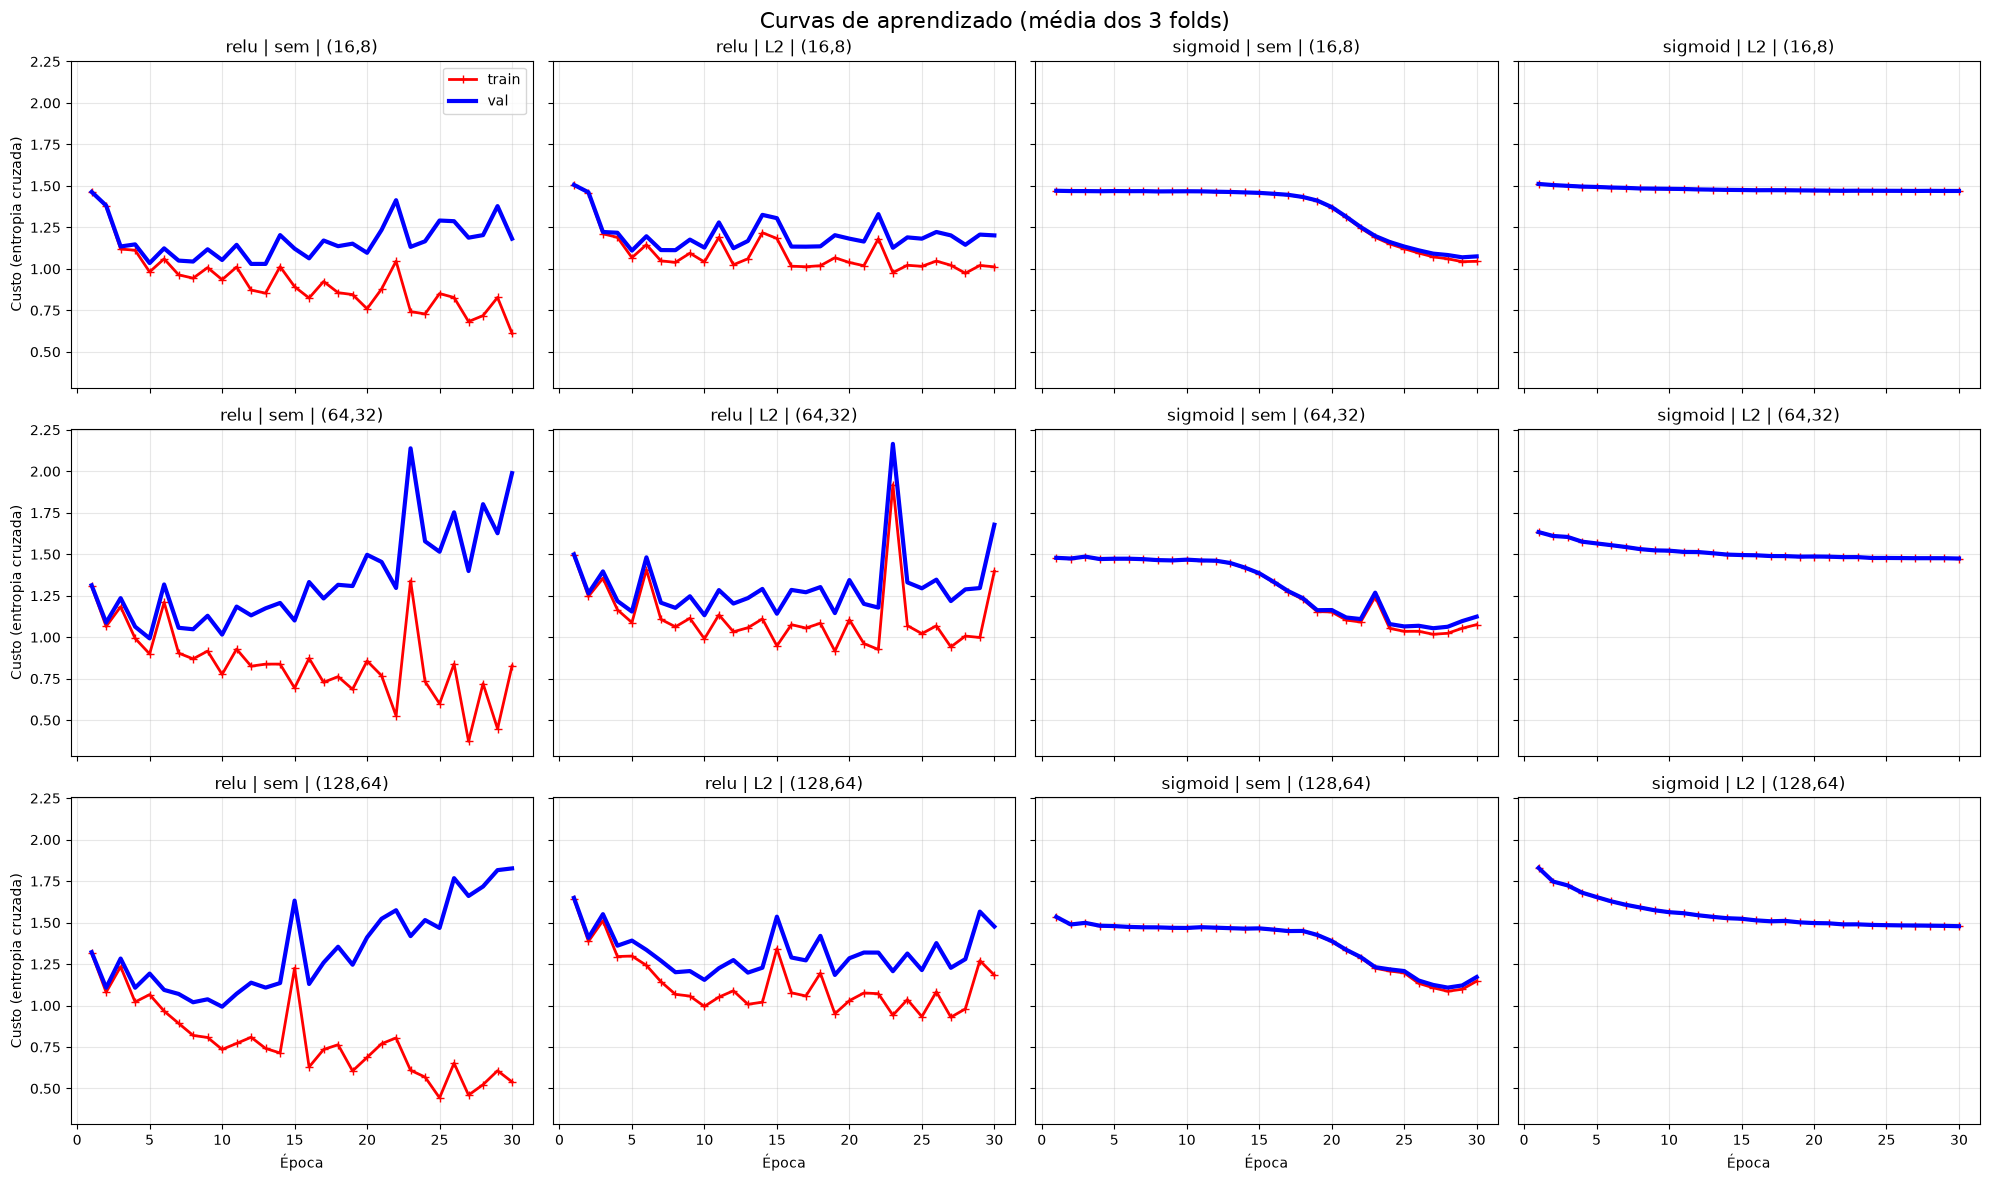

In [14]:
# ## Curvas de aprendizado das 12 configurações (custo × época)
# [Requisito: análise de overfitting, underfitting, viés e variância pelas curvas de aprendizado]
# Vermelho = custo no treino, azul = custo na validação, média dos 3 folds.
# Como ler: curvas que se afastam (treino cai, validação sobe) = overfitting / alta variância;
# curvas juntas mas altas = underfitting / alto viés.

fig, axes = plt.subplots(3, 4, figsize=(20, 12), sharex=True, sharey=True)   # linhas = neurônios, colunas = ativação + reg.
colunas = [(a, r) for a in ATIVACOES_GRID for r in REGULARIZACOES]
epocas = np.arange(1, EPOCAS + 1)
for lin, (n1, n2) in enumerate(NEURONIOS):
    for col, (ativacao, reg) in enumerate(colunas):
        h = historicos[f"{ativacao} | {reg} | ({n1},{n2})"]
        ax = axes[lin, col]
        ax.plot(epocas, h["custo_treino"], "r-+", linewidth=2, label="train")
        ax.plot(epocas, h["custo_val"], "b-", linewidth=3, label="val")
        ax.set_title(f"{ativacao} | {reg} | ({n1},{n2})")
        ax.grid(alpha=0.3)
        if lin == 2: ax.set_xlabel("Época")
        if col == 0: ax.set_ylabel("Custo (entropia cruzada)")
axes[0, 0].legend()
plt.suptitle("Curvas de aprendizado (média dos 3 folds)", fontsize=16)
plt.tight_layout()
plt.show()

In [15]:
# ## Resumo das curvas: custo final, gap (val − treino) e melhor época na validação
# [Requisito: viés e variância] Os números por trás do gráfico:
#   gap grande (validação muito acima do treino) → alta variância (overfitting);
#   custo de treino alto, mesmo com gap pequeno → alto viés (underfitting);
#   época do menor custo na validação → a partir dela a rede começa a decorar o treino.

resumo = []
for nome, h in historicos.items():
    resumo.append({"configuração": nome,
                   "custo treino": h["custo_treino"][-1], "custo val": h["custo_val"][-1],
                   "gap (val - treino)": h["custo_val"][-1] - h["custo_treino"][-1],
                   "menor custo val": h["custo_val"].min(), "época do menor custo val": int(h["custo_val"].argmin()) + 1})
pd.DataFrame(resumo).round(3)

,configuração,custo treino,custo val,gap (val - treino),menor custo val,época do menor custo val
0,"relu | sem | (16,8)",0.611,1.182,0.571,1.030,13
1,"relu | sem | (64,32)",0.827,1.989,1.162,0.993,5
2,"relu | sem | (128,64)",0.540,1.827,1.287,0.993,10
3,"relu | L2 | (16,8)",1.012,1.202,0.189,1.110,5
4,"relu | L2 | (64,32)",1.397,1.678,0.281,1.132,10
5,"relu | L2 | (128,64)",1.183,1.476,0.293,1.155,10
6,"sigmoid | sem | (16,8)",1.046,1.075,0.030,1.070,29
7,"sigmoid | sem | (64,32)",1.076,1.124,0.048,1.054,27
8,"sigmoid | sem | (128,64)",1.147,1.172,0.025,1.108,28
9,"sigmoid | L2 | (16,8)",1.470,1.470,-0.000,1.470,30


**Análise (viés e variância):**

* **ReLU sem regularização → overfitting (alta variância).** O custo de treino continua caindo, mas o de validação atinge o mínimo
  entre as épocas 5 e 13 e depois sobe. A distância final cresce com o tamanho da rede: 0,57 com (16, 8), 1,16 com (64, 32) e
  1,29 com (128, 64). Mais neurônios = mais capacidade = mais variância. As oscilações vêm da taxa de aprendizado alta (0,1).
* **ReLU com L2 → menos variância, mais viés.** A distância entre as curvas cai para 0,19–0,29, mas o custo de treino fica mais alto
  (1,0–1,4): a regularização segura os pesos e o modelo se ajusta menos ao treino.
* **Sigmoid sem regularização → underfitting (alto viés).** As curvas de treino e validação ficam praticamente juntas (distância ≤ 0,05,
  variância baixa), mas paradas em ~1,47 por 15 a 20 épocas e terminam em custo alto (1,05–1,15). Um platô assim é o
  sintoma do gradiente que "some" ao passar pelas camadas Sigmoid.
* **Sigmoid com L2 → underfitting extremo.** O custo praticamente não sai de ~1,47: o modelo só aprende a proporção das classes.

A melhor configuração é justamente a de menor capacidade com ReLU: ela tem a menor variância entre as ReLU sem regularização,
mantendo viés baixo.

# Modelo final: implementação própria × Keras

A melhor configuração é treinada no conjunto de desenvolvimento inteiro e avaliada no teste. A mesma
rede é montada em Keras com **os mesmos parâmetros**: mesmas camadas e ativações, softmax na saída,
`sparse_categorical_crossentropy`, SGD com a mesma taxa de aprendizado, mesmo batch, mesmas épocas,
mesma regularização L2 e inicialização Glorot. O teste aparece nas curvas apenas como acompanhamento
(não é usado em nenhuma decisão).

In [16]:
# ## Treino da implementação própria com a melhor configuração
# [Requisito: comparar com Keras] Primeiro lado da comparação: a nossa MLP, treinada no desenvolvimento
# inteiro com a melhor configuração e avaliada no teste (usado só agora, no final).
# O teste entra como "validação" apenas para registrar a curva; não influencia o treino nem as escolhas.

n1, n2 = MELHOR_NEUR
inicio = time.time()
nossa = MLP([X_dev.shape[1], n1, n2, 5], ativacao=MELHOR_ATIV, l2=REGULARIZACOES[MELHOR_REG],
            lr=LR, epocas=EPOCAS, batch=BATCH).fit(X_dev, y_dev, X_test, y_test)
tempo_nossa = time.time() - inicio
pred_nossa = nossa.predict(X_test)
print(f"Implementação própria: acc teste = {accuracy_score(y_test, pred_nossa):.3f} | "
      f"F1 macro teste = {f1_score(y_test, pred_nossa, average='macro'):.3f} | {tempo_nossa:.0f}s")

Implementação própria: acc teste = 0.553 | F1 macro teste = 0.479 | 4s


In [17]:
# ## Mesma rede em Keras, com os mesmos parâmetros
# [Requisito: compare com uma implementação usando Keras, com mesmos parâmetros]
# Mesma arquitetura (duas camadas Dense ocultas com os mesmos neurônios e ativação + saída softmax),
# mesma função de custo (entropia cruzada), mesmo otimizador (SGD com a mesma taxa), mesmo batch,
# mesmas épocas, mesma L2 e mesma inicialização (Glorot uniforme é o padrão das camadas Dense).

import tensorflow as tf
from tensorflow import keras

# Limpa sessões anteriores e fixa as sementes, para o resultado ser reproduzível.
keras.backend.clear_session()
np.random.seed(SEED)
tf.random.set_seed(SEED)

# kernel_regularizer=l2(λ) soma λ·ΣW² ao custo, igual à nossa implementação (só nos pesos, não no bias).
reg_keras = keras.regularizers.l2(REGULARIZACOES[MELHOR_REG]) if REGULARIZACOES[MELHOR_REG] > 0 else None
model = keras.models.Sequential()
model.add(keras.layers.Input(shape=(X_dev.shape[1],)))                                    # entrada: 3.000 termos
model.add(keras.layers.Dense(n1, activation=MELHOR_ATIV, kernel_regularizer=reg_keras))  # oculta 1
model.add(keras.layers.Dense(n2, activation=MELHOR_ATIV, kernel_regularizer=reg_keras))  # oculta 2
model.add(keras.layers.Dense(5, activation="softmax"))                                   # saída: 5 notas
# sparse_categorical_crossentropy = entropia cruzada com rótulos inteiros (0..4), como na nossa MLP.
model.compile(loss="sparse_categorical_crossentropy",
              optimizer=keras.optimizers.SGD(learning_rate=LR),
              metrics=["accuracy"])
model.summary()

inicio = time.time()
# O Keras recebe a matriz densa (toarray); a nossa implementação trabalha direto com a matriz esparsa.
history = model.fit(X_dev.toarray(), y_dev, epochs=EPOCAS, batch_size=BATCH,
                    validation_data=(X_test.toarray(), y_test), verbose=0)
tempo_keras = time.time() - inicio
pred_keras = model.predict(X_test.toarray(), verbose=0).argmax(axis=1)
print(f"Keras: acc teste = {accuracy_score(y_test, pred_keras):.3f} | "
      f"F1 macro teste = {f1_score(y_test, pred_keras, average='macro'):.3f} | {tempo_keras:.0f}s")

I0000 00:00:1793630913.580346    6618 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793630913.584012    6618 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793630913.976682    6618 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793630916.612442    6618 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793630916.619066    6618 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


E0000 00:00:1793630917.886793    6618 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793630917.888261    7230 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1793630917.936039    6618 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │        48,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │            45 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,197 (188.27 KB)

 Trainable params: 48,197 (188.27 KB)

 Non-trainable params: 0 (0.00 B)

Keras: acc teste = 0.498 | F1 macro teste = 0.453 | 44s


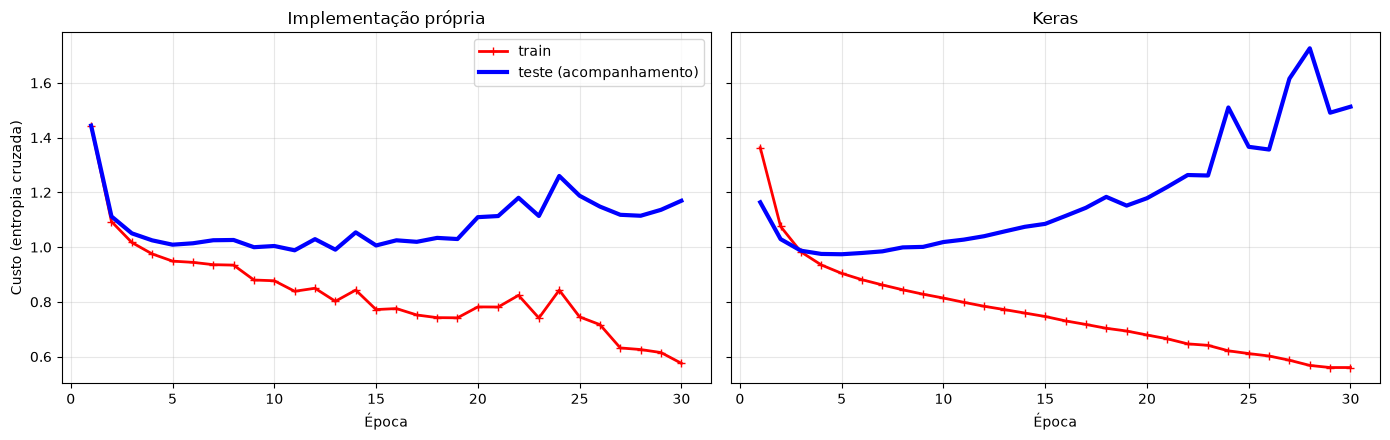

,acurácia,F1 macro,custo final treino,tempo (s)
modelo,,,,
Implementação própria,0.553,0.479,0.576,3.907
Keras,0.498,0.453,0.560,43.510


In [18]:
# ## Comparação: curvas de custo e métricas no teste
# [Requisito: comparar com Keras] Lado a lado: as curvas de custo das duas implementações e uma tabela
# com acurácia, F1 macro, custo final de treino e tempo. Custos de treino parecidos indicam que as
# duas aprendem da mesma forma.

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (titulo, tr, va) in zip(axes, [
        ("Implementação própria", nossa.hist["custo_treino"], nossa.hist["custo_val"]),
        ("Keras", history.history["loss"], history.history["val_loss"])]):
    ax.plot(epocas, tr, "r-+", linewidth=2, label="train")
    ax.plot(epocas, va, "b-", linewidth=3, label="teste (acompanhamento)")
    ax.set_title(titulo); ax.set_xlabel("Época"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Custo (entropia cruzada)")
axes[0].legend()
plt.tight_layout()
plt.show()

comparacao = pd.DataFrame([
    {"modelo": "Implementação própria", "acurácia": accuracy_score(y_test, pred_nossa),
     "F1 macro": f1_score(y_test, pred_nossa, average="macro"), "custo final treino": nossa.hist["custo_treino"][-1], "tempo (s)": tempo_nossa},
    {"modelo": "Keras", "acurácia": accuracy_score(y_test, pred_keras),
     "F1 macro": f1_score(y_test, pred_keras, average="macro"), "custo final treino": history.history["loss"][-1], "tempo (s)": tempo_keras},
]).set_index("modelo")
comparacao.round(3)

              precision    recall  f1-score   support

   1 estrela      0.706     0.811     0.755       777
  2 estrelas      0.290     0.242     0.264       252
  3 estrelas      0.383     0.272     0.318       500
  4 estrelas      0.417     0.413     0.415      1003
  5 estrelas      0.626     0.661     0.643      1468

    accuracy                          0.553      4000
   macro avg      0.485     0.480     0.479      4000
weighted avg      0.538     0.553     0.543      4000



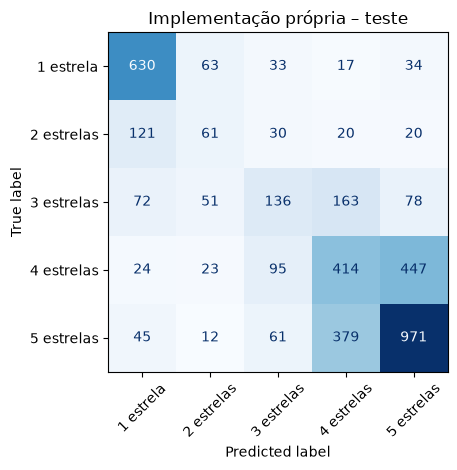

In [19]:
# ## Relatório por classe e matriz de confusão da implementação própria no teste
# Mostra em quais notas a rede acerta e erra. Numa base desbalanceada, olhar só a acurácia esconde
# o desempenho ruim nas classes pequenas (2 e 3 estrelas).

from sklearn.metrics import classification_report, ConfusionMatrixDisplay

notas = ["1 estrela", "2 estrelas", "3 estrelas", "4 estrelas", "5 estrelas"]
# precision, recall e F1 de cada nota, mais as médias macro e ponderada.
print(classification_report(y_test, pred_nossa, target_names=notas, digits=3, zero_division=0))
# Linhas = nota real, colunas = nota prevista; fora da diagonal estão os erros.
ConfusionMatrixDisplay.from_predictions(y_test, pred_nossa, display_labels=notas, cmap="Blues",
                                        xticks_rotation=45, colorbar=False)
plt.title("Implementação própria – teste")
plt.tight_layout()
plt.show()

**Análise:** as duas implementações, com os mesmos hiperparâmetros, mostram o mesmo comportamento: o custo de treino cai até
~0,56–0,58 e o custo no teste atinge o mínimo (~1,0) por volta da 5ª época e depois sobe – overfitting. O custo final de treino é
praticamente igual (0,576 × 0,560), o que confirma que a rede própria aprende como a do Keras.

As métricas no teste diferem (acurácia 0,553 × 0,498; F1 macro 0,479 × 0,453) porque os pesos iniciais e a ordem dos mini-batches
são sorteados de forma diferente em cada biblioteca, e com taxa 0,1 a ReLU oscila bastante de uma época para outra; no Keras a 30ª
época caiu num ponto de maior overfitting. Interromper o treino perto da 5ª época (early stopping) beneficiaria as duas.
A implementação própria foi mais rápida (4 s × 44 s) por usar o TF-IDF esparso, enquanto o Keras recebeu a matriz densa.

**Por classe:** 1 estrela (F1 0,755) e 5 estrelas (0,643) são as mais fáceis; 2 estrelas (0,264) e 3 estrelas (0,318) as mais
difíceis. A matriz de confusão mostra que os erros caem quase sempre em notas **vizinhas**: 2 estrelas vira 1 (121 casos), e 4 e 5
estrelas se confundem muito (447 e 379 casos).

# Mapa de calor da variação dos pesos: ReLU × Sigmoid

Duas redes iguais à melhor configuração, mudando só a ativação. Em cada época, as duas matrizes de pesos
das camadas ocultas ($W^{(1)}$: entrada → oculta 1 e $W^{(2)}$: oculta 1 → oculta 2) mudam; a variação
$|W_{época} - W_{época-1}|$ é **acumulada** ao longo das 30 épocas. Como $W^{(1)}$ tem 3.000 linhas
(uma por termo), o mapa mostra os 30 termos mais frequentes.

In [20]:
# ## Treino das duas redes (ReLU e Sigmoid) com os demais parâmetros iguais
# [Requisito: mapa de calor comparando ReLU e Sigmoid] Duas redes idênticas à melhor configuração
# (mesmos neurônios, regularização, taxa, batch e épocas), mudando SÓ a ativação. Assim a diferença
# nos pesos vem apenas da função de ativação. Durante o fit, cada rede guarda a variação dos pesos por época.

redes_ativ = {}
for ativacao in ["relu", "sigmoid"]:
    redes_ativ[ativacao] = MLP([X_dev.shape[1], n1, n2, 5], ativacao=ativacao, l2=REGULARIZACOES[MELHOR_REG],
                               lr=LR, epocas=EPOCAS, batch=BATCH).fit(X_dev, y_dev, X_test, y_test)
    p = redes_ativ[ativacao].predict(X_test)
    print(f"{ativacao:8s} F1 macro teste = {f1_score(y_test, p, average='macro'):.3f}")

relu     F1 macro teste = 0.479


sigmoid  F1 macro teste = 0.368


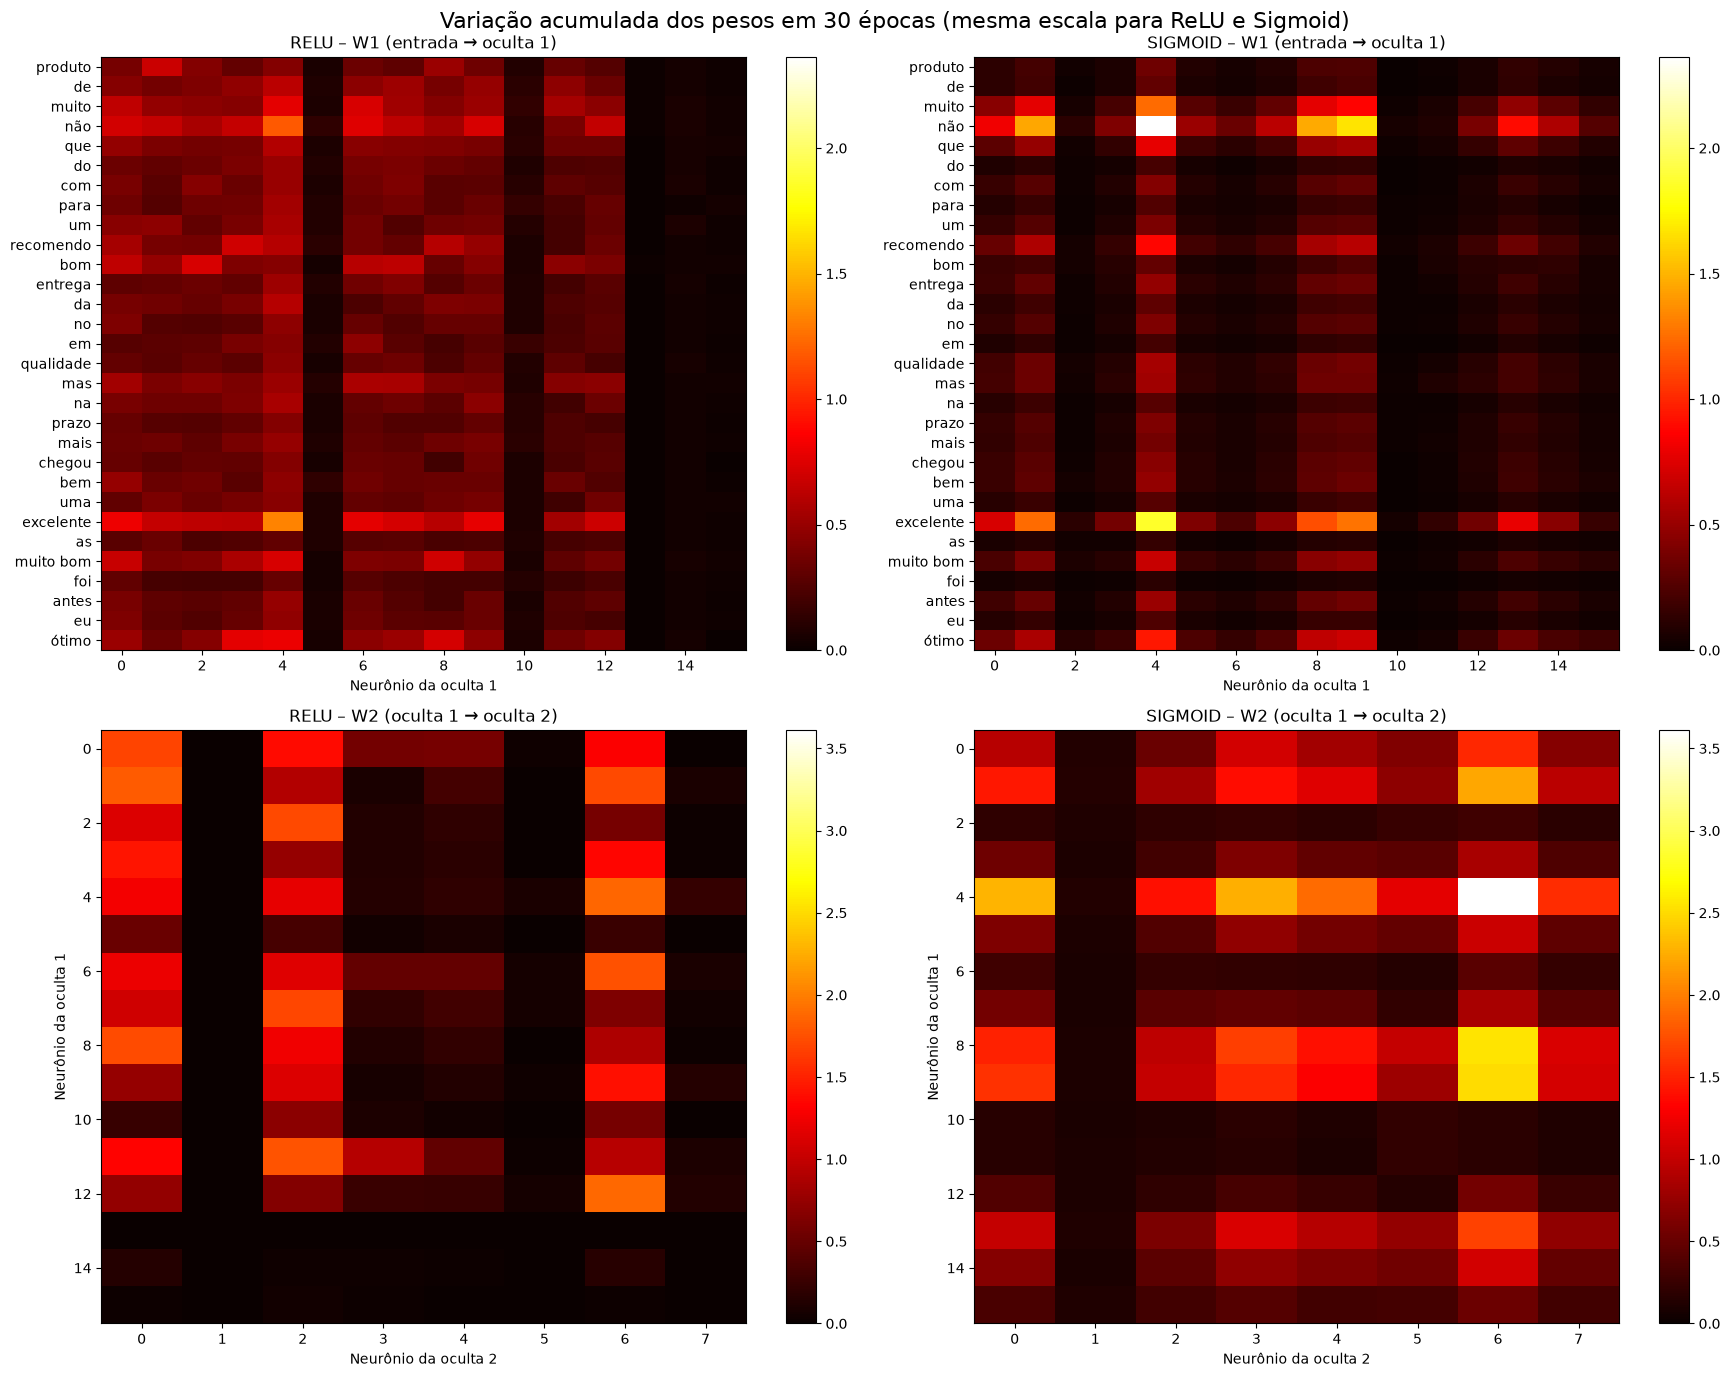

In [21]:
# ## Mapas de calor da variação acumulada |ΔW| em W1 (30 termos mais frequentes) e W2
# [Requisito: "em cada época você tem duas matrizes ... acumule esses números para mostrar a variação"]
# As duas matrizes são W1 (entrada → oculta 1) e W2 (oculta 1 → oculta 2). Cada célula é o quanto aquele
# peso mudou, somado nas 30 épocas: quanto mais clara, mais o peso mudou.
# Coluna da esquerda = ReLU, coluna da direita = Sigmoid, na MESMA escala de cor para poder comparar.

# W1 tem 3.000 linhas (uma por termo do TF-IDF); para caber no gráfico mostramos os 30 termos que
# aparecem em mais avaliações.
top_termos = np.argsort(np.asarray((X_dev > 0).sum(axis=0)).ravel())[::-1][:30]

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
for col, ativacao in enumerate(["relu", "sigmoid"]):
    var = redes_ativ[ativacao].variacao
    # vmax comum às duas ativações: garante a mesma escala de cor na comparação.
    vmax1 = max(redes_ativ[a].variacao[0][top_termos].max() for a in redes_ativ)
    vmax2 = max(redes_ativ[a].variacao[1].max() for a in redes_ativ)
    im = axes[0, col].imshow(var[0][top_termos], aspect="auto", cmap="hot", vmin=0, vmax=vmax1)
    axes[0, col].set_yticks(range(30)); axes[0, col].set_yticklabels(termos[top_termos])
    axes[0, col].set_xlabel("Neurônio da oculta 1"); axes[0, col].set_title(f"{ativacao.upper()} – W1 (entrada → oculta 1)")
    fig.colorbar(im, ax=axes[0, col])
    im = axes[1, col].imshow(var[1], aspect="auto", cmap="hot", vmin=0, vmax=vmax2)
    axes[1, col].set_xlabel("Neurônio da oculta 2"); axes[1, col].set_ylabel("Neurônio da oculta 1")
    axes[1, col].set_title(f"{ativacao.upper()} – W2 (oculta 1 → oculta 2)")
    fig.colorbar(im, ax=axes[1, col])
plt.suptitle("Variação acumulada dos pesos em 30 épocas (mesma escala para ReLU e Sigmoid)", fontsize=16)
plt.tight_layout()
plt.show()

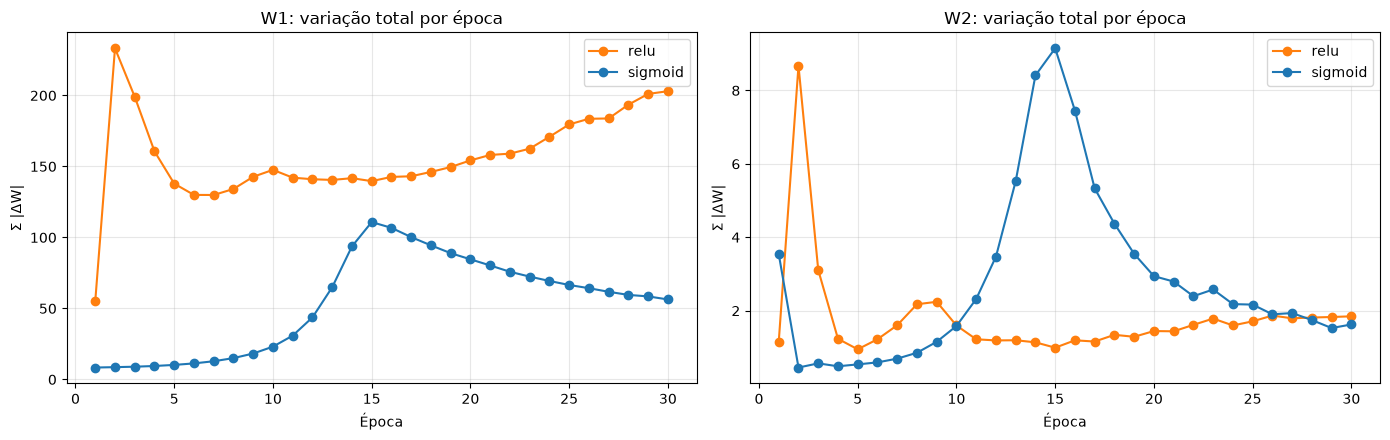

relu     variação acumulada total: W1 = 4705.5 | W2 = 53.4 | W3 = 34.1
sigmoid  variação acumulada total: W1 = 1609.8 | W2 = 83.8 | W3 = 63.5


In [22]:
# ## Quanto os pesos mudam em cada época (Σ|ΔW| por camada)
# Complemento do mapa de calor: em vez do acumulado, mostra a variação total de W1 e W2 época a época.
# Ajuda a ver QUANDO cada rede aprende (ex.: a Sigmoid quase não mexe em W1 nas primeiras épocas).
# Base para a análise de saturação da próxima seção.

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for i, ax in enumerate(axes):
    for ativacao, cor in [("relu", "tab:orange"), ("sigmoid", "tab:blue")]:
        ax.plot(epocas, np.array(redes_ativ[ativacao].variacao_epoca)[:, i], "-o", color=cor, label=ativacao)
    ax.set_title(f"W{i + 1}: variação total por época"); ax.set_xlabel("Época"); ax.set_ylabel("Σ |ΔW|")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

# Totais acumulados nas 30 épocas, para cada matriz de pesos (W3 = oculta 2 → saída).
for ativacao in ["relu", "sigmoid"]:
    total = [v.sum() for v in redes_ativ[ativacao].variacao]
    print(f"{ativacao:8s} variação acumulada total: W1 = {total[0]:.1f} | W2 = {total[1]:.1f} | W3 = {total[2]:.1f}")

**Análise:**

* **Quanto mudam:** com ReLU, $W^{(1)}$ variou ~3 vezes mais que com Sigmoid (4.706 × 1.610 no acumulado). A Sigmoid muda mais em
  $W^{(2)}$ e $W^{(3)}$, perto da saída.
* **Quando mudam:** na Sigmoid, $W^{(1)}$ quase não muda nas 10 primeiras épocas (Σ|ΔW| ≈ 10 por época contra ~150 na ReLU), só
  "destrava" por volta da época 12–15 e depois volta a desacelerar. É o mesmo platô visto na curva de aprendizado: o erro chega
  enfraquecido à primeira camada, porque cada camada Sigmoid multiplica o gradiente por $f'(z) \le 0{,}25$.
* **Onde mudam:** na Sigmoid a variação se concentra em poucos neurônios (ex.: 4, 8 e 9 da oculta 1) e em palavras de opinião
  ("não", "excelente", "muito", "recomendo"); o resto da matriz fica quase parado. Na ReLU a variação é espalhada, mas alguns
  neurônios ficam quase sem mudança (colunas escuras: neurônios 5 e 13–15 da oculta 1; 1, 5 e 7 da oculta 2) – são neurônios que
  quase nunca ativam, logo a derivada é 0 e seus pesos não são atualizados. As linhas escuras de $W^{(2)}$ na ReLU (13–15) são os pesos
  que saem desses mesmos neurônios.

# Saturação dos pesos

Um neurônio **satura** quando sua entrada $z$ cai numa região em que a derivada da ativação é (quase)
zero: o erro que volta pelo backpropagation é multiplicado por $f'(z) \approx 0$ e os pesos que chegam
nele quase não mudam.

* **Sigmoid:** $f'(z) = f(z)(1 - f(z)) \le 0{,}25$; satura quando a saída fica perto de 0 ou de 1.
* **ReLU:** $f'(z) = 1$ para $z > 0$ (não satura) e $0$ para $z \le 0$; um neurônio que fica sempre em zero está "morto".

In [23]:
# ## Medidas de saturação nas camadas ocultas (no teste)
# [Requisito: "a partir do experimento anterior, faça uma análise sobre a saturação dos pesos"]
# Um neurônio satura quando a derivada da ativação fica perto de zero: o erro que volta pelo
# backpropagation quase some e os pesos que chegam nele param de mudar (o que o mapa de calor mostrou).
# Medimos, para cada camada oculta:
#   Sigmoid → % de saídas nos extremos (< 0,05 ou > 0,95), onde a derivada é quase zero;
#   ReLU    → % de saídas iguais a 0 (derivada zero) e % de neurônios "mortos" (zero para todas as avaliações);
#   derivada média f'(z): na Sigmoid nunca passa de 0,25; na ReLU é 0 ou 1.

linhas = []
for ativacao, rede in redes_ativ.items():
    zs, ativs = rede.forward(X_test)                 # z e saídas de cada camada para as avaliações do teste
    for camada in [0, 1]:                            # as duas camadas ocultas
        z, a = zs[camada], ativs[camada + 1]
        deriv = rede.f_derivada(z)
        if ativacao == "sigmoid":
            saturados = ((a < 0.05) | (a > 0.95)).mean()
            mortos = np.nan
        else:
            saturados = (a == 0).mean()
            mortos = (a.max(axis=0) == 0).mean()     # neurônio que nunca ativou em nenhuma avaliação
        linhas.append({"ativação": ativacao, "camada": f"oculta {camada + 1}",
                       "% saídas saturadas (sigmoid <0,05 ou >0,95 | relu = 0)": 100 * saturados,
                       "% neurônios mortos (relu)": 100 * mortos,
                       "derivada média f'(z)": deriv.mean()})
pd.DataFrame(linhas).round(3)

,ativação,camada,"% saídas saturadas (sigmoid <0,05 ou >0,95 | relu = 0)",% neurônios mortos (relu),derivada média f'(z)
0,relu,oculta 1,48.939,0.0,0.511
1,relu,oculta 2,51.569,0.0,0.484
2,sigmoid,oculta 1,0.000,NaN,0.248
3,sigmoid,oculta 2,0.203,NaN,0.215


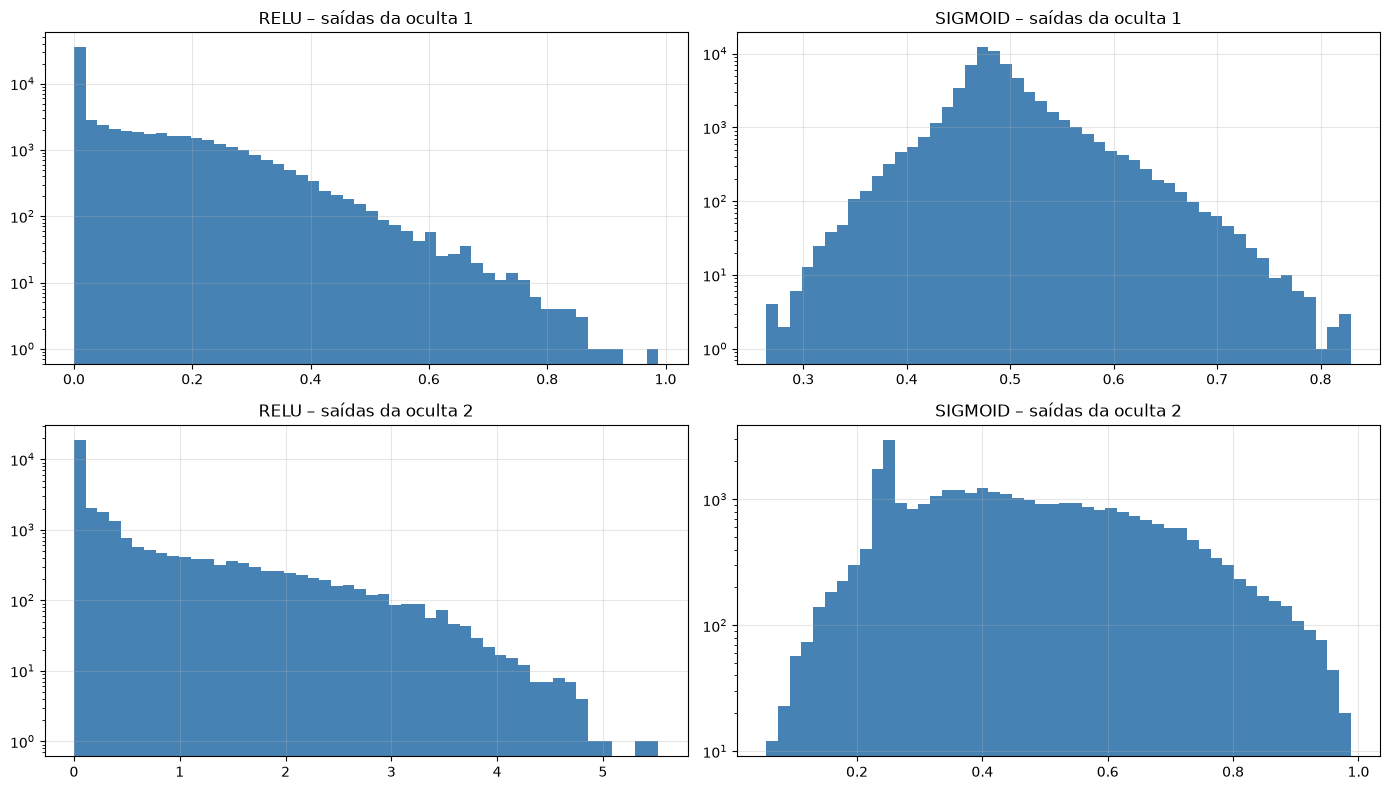

In [24]:
# ## Distribuição das saídas dos neurônios ocultos (no teste)
# [Requisito: análise de saturação] Histogramas das saídas de cada camada oculta. Na Sigmoid, saturação
# apareceria como acúmulo perto de 0 e de 1; na ReLU, o pico em 0 são os neurônios desligados.
# Eixo Y em escala log para enxergar também as faixas com poucas saídas.

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for col, (ativacao, rede) in enumerate(redes_ativ.items()):
    zs, ativs = rede.forward(X_test)
    for lin in [0, 1]:
        axes[lin, col].hist(ativs[lin + 1].ravel(), bins=50, color="steelblue")
        axes[lin, col].set_title(f"{ativacao.upper()} – saídas da oculta {lin + 1}")
        axes[lin, col].set_yscale("log"); axes[lin, col].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Análise:**

* **Sigmoid:** as saídas ficam concentradas perto de 0,5 (oculta 1 entre 0,26 e 0,83) e praticamente nenhuma está nas regiões
  saturadas (0% e 0,2%). A derivada média é 0,248, quase o máximo de 0,25. Ou seja, nesta rede a lentidão da Sigmoid **não vem de
  neurônios saturados nos extremos**, e sim do próprio limite da derivada: mesmo no melhor caso, o erro é dividido por 4 a cada camada,
  e os pesos das primeiras camadas mudam pouco (o platô e o mapa de calor). Com L2, os pesos são puxados para zero, $z \approx 0$,
  todas as saídas ficam em 0,5 e a rede não consegue diferenciar as avaliações – por isso a Sigmoid com L2 não aprendeu.
* **ReLU:** cerca de 50% das saídas são exatamente 0 (derivada 0), mas não há neurônio morto (todos ativam para alguma avaliação
  do teste). Quando o neurônio está ativo a derivada é 1, então o erro passa sem enfraquecer; por isso a ReLU aprende rápido. O lado
  ruim aparece no mapa de calor: neurônios que raramente ativam quase não têm seus pesos atualizados.

# Ponto extra: embedding Skip-gram com a própria implementação

O Skip-gram é uma rede com **uma camada oculta**: a entrada é a palavra central em one-hot, a camada
oculta (sem ativação) é o embedding e a saída é um softmax sobre o vocabulário, que prevê as palavras
do contexto. Por isso a mesma classe `MLP` é usada, com uma camada a menos: `[V, 50, V]` e ativação linear.
Depois do treino, a linha $i$ de $W^{(1)}$ é o vetor da palavra $i$.

In [25]:
# ## Pares (palavra central, palavra de contexto) a partir dos textos do desenvolvimento
# [Requisito extra: embedding Skip-gram] O Skip-gram aprende o vetor de uma palavra tentando prever as
# palavras vizinhas a partir dela. Aqui montamos os exemplos de treino: para cada palavra (centro), as
# palavras até 2 posições antes e depois (contexto).

from sklearn.feature_extraction.text import CountVectorizer
from scipy import sparse

V, DIM, JANELA = 2000, 50, 2          # vocabulário, tamanho do vetor de cada palavra, janela de contexto
# O CountVectorizer só é usado para montar o vocabulário (2.000 palavras mais frequentes) e quebrar o texto em palavras.
contador = CountVectorizer(max_features=V, lowercase=True, token_pattern=r"(?u)\b[^\W\d_]{2,}\b").fit(X_dev_txt)
vocab = contador.vocabulary_                      # palavra → índice
palavras = contador.get_feature_names_out()       # índice → palavra
tokenizar = contador.build_analyzer()

centros, contextos = [], []
for texto in X_dev_txt:
    ids = [vocab[t] for t in tokenizar(texto) if t in vocab]
    for i, c in enumerate(ids):
        for j in range(max(0, i - JANELA), min(len(ids), i + JANELA + 1)):
            if j != i:
                centros.append(c); contextos.append(ids[j])
centros, contextos = np.array(centros), np.array(contextos)
# Entrada da rede: palavra central em one-hot (1 na coluna da palavra, 0 no resto), em matriz esparsa.
X_sg = sparse.csr_matrix((np.ones(len(centros), dtype=np.float32), (np.arange(len(centros)), centros)), shape=(len(centros), V))
print(f"Vocabulário: {V} palavras | pares de treino: {len(centros)}")

Vocabulário: 2000 palavras | pares de treino: 1029686


In [26]:
# ## Treino do Skip-gram com a classe MLP (uma camada oculta, linear)
# [Requisito extra: "a partir da implementação feita ... retire uma camada"] Usa a MESMA classe MLP,
# agora com UMA camada oculta: [V, 50, V].
#   entrada  = palavra central (one-hot, V = 2.000);
#   oculta   = 50 neurônios sem função de ativação (linear): é o embedding;
#   saída    = softmax sobre o vocabulário, que prevê a palavra de contexto.
# Taxa de aprendizado e batch maiores porque são cerca de 1 milhão de pares.

inicio = time.time()
skipgram = MLP([V, DIM, V], ativacao="linear", lr=1.0, epocas=5, batch=256).fit(X_sg, contextos, historico=False)
print(f"Treino em {time.time() - inicio:.0f}s | custo final: {skipgram.custo(X_sg[:50000], contextos[:50000]):.3f}")
# Depois do treino, os pesos da entrada para a camada oculta são os vetores das palavras.
embedding = skipgram.W[0]                          # (V × 50): uma linha por palavra

Treino em 78s | custo final: 5.718


In [27]:
# ## Conferência: palavras mais próximas (similaridade do cosseno)
# Verifica se o embedding aprendeu algo com sentido: palavras de significado parecido devem ter vetores
# parecidos (cosseno perto de 1).

normas = embedding / np.linalg.norm(embedding, axis=1, keepdims=True)   # normaliza cada vetor (tamanho 1)
for palavra in ["ótimo", "péssimo", "entrega", "recomendo", "defeito"]:
    if palavra in vocab:
        sim = normas @ normas[vocab[palavra]]                 # cosseno com todas as palavras
        vizinhas = [palavras[i] for i in np.argsort(sim)[::-1][1:7]]   # 6 mais parecidas (pula a própria)
        print(f"{palavra:10s} → {', '.join(vizinhas)}")

ótimo      → otimo, excelente, bom, maravilhoso, top, incrível
péssimo    → horrível, deste, falsificado, excelente, falso, ótimo
entrega    → entregue, previsto, combinado, entregou, solicitado, chegou
recomendo  → indico, recomento, recomendado, recomendaria, adorei, cumpriu
defeito    → quebrado, quebrada, errada, amassada, faltando, preto


In [28]:
# ## Representação de cada avaliação: média dos embeddings das palavras
# [Requisito extra: "substitua a representação TF-IDF com a nova representação concatenada"]
# Cada avaliação vira a média dos vetores Skip-gram das suas palavras (50 números). Essa média é
# concatenada (colada ao lado) do TF-IDF, formando a nova entrada da MLP: 3.000 + 50 = 3.050 valores.

def media_embedding(textos):
    M = np.zeros((len(textos), DIM), dtype=np.float32)
    for k, texto in enumerate(textos):
        ids = [vocab[t] for t in tokenizar(texto) if t in vocab]
        if ids:                                    # avaliações sem palavras do vocabulário ficam com zeros
            M[k] = embedding[ids].mean(axis=0)
    return M

E_dev, E_test = media_embedding(X_dev_txt), media_embedding(X_test_txt)
X_dev_conc = sparse.hstack([X_dev, sparse.csr_matrix(E_dev)]).tocsr()     # TF-IDF + Skip-gram
X_test_conc = sparse.hstack([X_test, sparse.csr_matrix(E_test)]).tocsr()
print("Concatenada:", X_dev_conc.shape)

Concatenada: (16000, 3050)


In [29]:
# ## Melhor configuração com a nova representação × TF-IDF
# [Requisito extra: "utilize a melhor configuração de parâmetros e veja se a acurácia melhorou"]
# Treina a MLP de duas camadas com a melhor configuração do 3-fold CV, trocando só a entrada,
# e compara a acurácia no teste com o modelo final em TF-IDF.

# Linha de referência: o modelo final com TF-IDF (já treinado antes).
linhas = [{"representação": "TF-IDF (modelo final)", "dimensão": X_dev.shape[1],
           "acurácia": accuracy_score(y_test, pred_nossa), "F1 macro": f1_score(y_test, pred_nossa, average="macro")}]
# A comparação principal é a "concatenada"; o "Skip-gram (média)" sozinho é um complemento.
for nome, (Xd, Xt) in {"Skip-gram (média)": (E_dev, E_test),
                        "TF-IDF + Skip-gram (concatenada)": (X_dev_conc, X_test_conc)}.items():
    rede = MLP([Xd.shape[1], n1, n2, 5], ativacao=MELHOR_ATIV, l2=REGULARIZACOES[MELHOR_REG],
               lr=LR, epocas=EPOCAS, batch=BATCH).fit(Xd, y_dev, historico=False)
    p = rede.predict(Xt)
    linhas.append({"representação": nome, "dimensão": Xd.shape[1],
                   "acurácia": accuracy_score(y_test, p), "F1 macro": f1_score(y_test, p, average="macro")})
pd.DataFrame(linhas).set_index("representação").round(3)

,dimensão,acurácia,F1 macro
representação,,,
TF-IDF (modelo final),3000,0.553,0.479
Skip-gram (média),50,0.536,0.370
TF-IDF + Skip-gram (concatenada),3050,0.522,0.461


**Análise:** o Skip-gram treinado com a própria implementação aprendeu relações coerentes: "ótimo" ficou perto de
"excelente, bom, maravilhoso", "entrega" perto de "entregue, previsto, chegou" e "defeito" perto de "quebrado, amassada, faltando".
Ainda assim, **a acurácia não melhorou**:

* Só o Skip-gram (média dos vetores, 50 dimensões) caiu para acurácia 0,536 e F1 macro 0,370: a média mistura as palavras e
  perde termos decisivos, como "não" junto de "recomendo".
* A concatenação TF-IDF + Skip-gram ficou em 0,522 / 0,461, também abaixo do TF-IDF puro (0,553 / 0,479).

Com apenas ~1 milhão de pares, vocabulário de 2.000 palavras e 5 épocas, o embedding não acrescenta informação que o TF-IDF já
não tenha para esta tarefa.

# Conclusão

* A **MLP de duas camadas implementada do zero** (forward, backpropagation pela regra da cadeia e gradiente descendente)
  calcula corretamente as derivadas de pesos e bias (diferença de ~$10^{-10}$ para a derivada numérica) e aprende como a mesma rede em Keras.
* Pelo **3-fold cross-validation**, a melhor configuração foi **ReLU, sem regularização, (16, 8) neurônios**: F1 macro 0,479 e
  acurácia 0,553 no teste, numa base difícil (5 classes desbalanceadas, notas vizinhas parecidas).
* **Curvas de aprendizado:** ReLU sem regularização tende ao **overfitting** (variância alta, maior com mais neurônios); a **L2** reduz a
  variância, mas com λ = 0,001 aumentou demais o viés; a **Sigmoid** ficou em **underfitting**, com treino e validação juntos e altos.
* **Pesos:** com Sigmoid, a primeira camada muda pouco e devagar, porque a derivada ($\le 0{,}25$) enfraquece o erro a cada camada;
  com ReLU o erro passa inteiro pelos neurônios ativos, mas os que quase nunca ativam ficam com os pesos parados.
* **Ponto extra:** o Skip-gram aprendeu boas relações entre palavras, mas não melhorou a acurácia em relação ao TF-IDF.
* Limitações: amostra de 20 mil avaliações, taxa de aprendizado fixa (0,1) e treino sem early stopping.